In [644]:
import pandas as pd
import numpy as np
import missingno as msno

In [645]:
df = pd.read_csv(r'/home/ziyad/Desktop/IA_DATA_2026_2027/02_ISMO_COURS_ET_TP/Principale/analyse des donnees/project_groupe_exam/Student_Performance_raw.csv' , index_col=0)

In [646]:
df.head()

,race/ethnicity,parental level of education,lunch,test preparation course,math percentage,reading score percentage,writing score percentage,sex
108,group C,associate's degree,standard,none,0.71,0.82,0.72,F
183,group C,high school,standard,none,0.85,0.78,0.75,F
106,group D,associate's degree,standard,completed,NaN,0.76,0.76,F
107,group C,high school,free/reduced,completed,0.41,0.36,0.34,F
51,NaN,bachelor's degree,free/reduced,completed,0.58,0.63,0.58,F


In [647]:
df.dtypes

race/ethnicity                     str
parental level of education        str
lunch                              str
test preparation course            str
math percentage                float64
reading score percentage       float64
writing score percentage       float64
sex                                str
dtype: object

In [648]:
df.shape

(214, 8)

In [649]:
df = df.drop_duplicates()

In [650]:
df.shape

(200, 8)

In [651]:
pourcentage_des_manquante_avant = df.isnull().mean()*100

<Axes: >

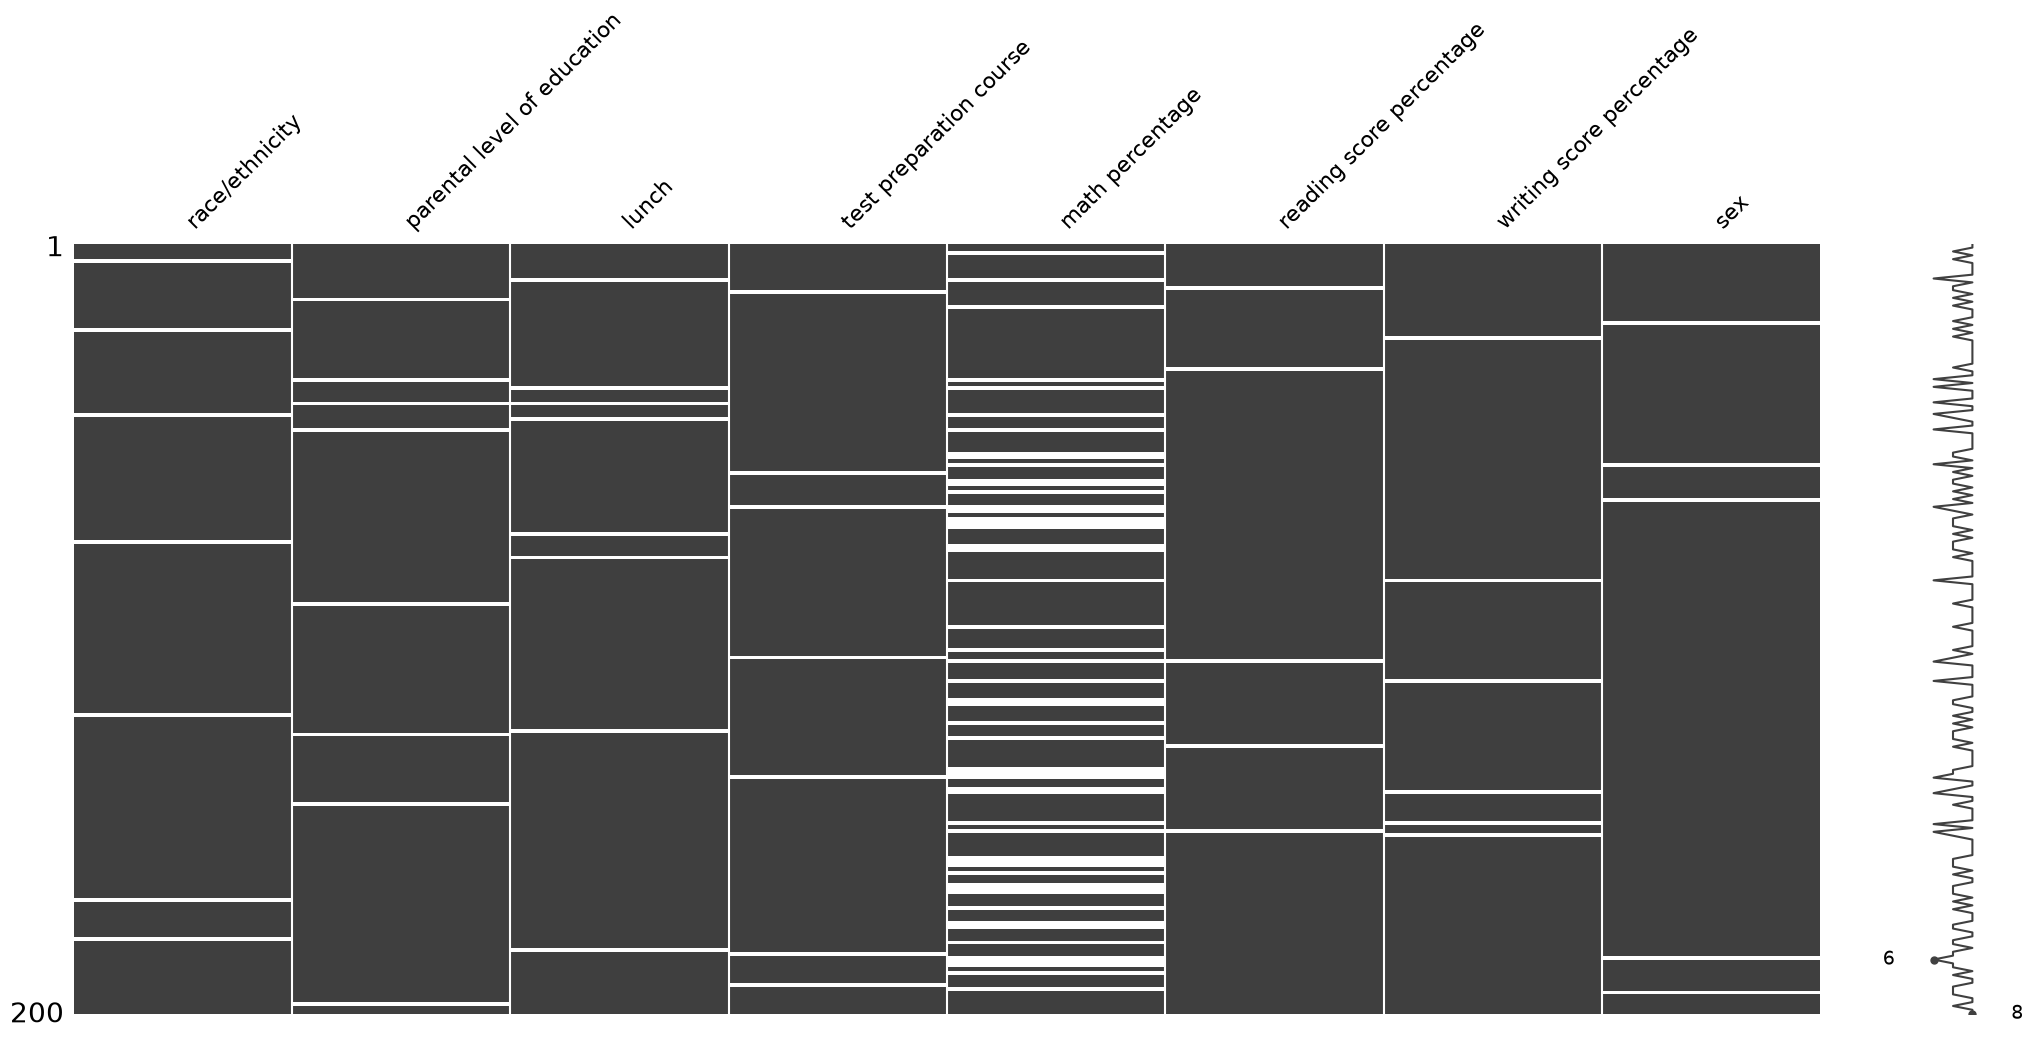

In [652]:
msno.matrix(df)

In [653]:
df_num = df.select_dtypes(include = 'number')
df_cat = df.select_dtypes(include = 'str')

In [654]:
df['sex'].value_counts()

sex
F         98
M         95
Female     1
X          1
Name: count, dtype: int64

In [655]:
df['sex'] = df['sex'].str.replace('Female' , 'F')
df['sex'] = df['sex'].replace('X' , np.nan)
df['sex'].value_counts()

sex
F    99
M    95
Name: count, dtype: int64

In [656]:
df[['math percentage', 'reading score percentage', 'writing score percentage']].agg(['min' , 'max'])

,math percentage,reading score percentage,writing score percentage
min,-0.3,-0.15,0.0
max,5.6,2.10,9.9


In [657]:
resultat = []
for i in df_num:
    q1 , q3 = df_num[i].quantile([0.25,0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df_num[(df_num[i] < bas) | (df_num[i] > haut)][i]
    resultat.append({"colonne": i, "borne_basse": bas,
                   "borne_haute": haut, "nb_aberrantes": len(out)})
print(pd.DataFrame(resultat))

                    colonne  borne_basse  borne_haute  nb_aberrantes
0           math percentage       0.2725       1.0525              3
1  reading score percentage       0.3000       1.1000              3
2  writing score percentage       0.3200       1.0400              3


In [658]:
score_cols = ['math percentage', 'reading score percentage', 'writing score percentage']
for col in score_cols:
    nb_outliers = ((df[col] <= 0) | (df[col] > 1)).sum()
    print(f"Nombre de valeurs aberrantes dans '{col}' : {nb_outliers}")

Nombre de valeurs aberrantes dans 'math percentage' : 3
Nombre de valeurs aberrantes dans 'reading score percentage' : 2
Nombre de valeurs aberrantes dans 'writing score percentage' : 3


In [659]:
for col in score_cols:
    df.loc[(df[col] < 0) | (df[col] > 1), col] = np.nan

In [660]:
df[['math percentage', 'reading score percentage', 'writing score percentage']].agg(['min' , 'max'])

,math percentage,reading score percentage,writing score percentage
min,0.36,0.29,0.0
max,1.00,1.00,1.0


In [661]:
pourcentage_des_manquante_apres = df.isnull().mean()*100

In [662]:
pd.concat([pourcentage_des_manquante_avant , pourcentage_des_manquante_apres] , axis = 1 , 
          keys = ['pourcentage des manquante avant traitement des valeurs aberrantes' ,'pourcentage des manquante apres traitement des valeurs aberrantes'] )

,pourcentage des manquante avant traitement des valeurs aberrantes,pourcentage des manquante apres traitement des valeurs aberrantes
race/ethnicity,3.5,3.5
parental level of education,4.0,4.0
lunch,4.0,4.0
test preparation course,3.5,3.5
math percentage,26.0,27.5
reading score percentage,2.5,3.5
writing score percentage,3.0,4.0
sex,2.5,3.0


In [663]:
missing_pct = df.select_dtypes(include='number').isnull().mean() * 100
print("Pourcentage de valeurs manquantes par colonne :\n", missing_pct)

Pourcentage de valeurs manquantes par colonne :
 math percentage             27.5
reading score percentage     3.5
writing score percentage     4.0
dtype: float64


In [664]:
score_cols = ['reading score percentage', 'writing score percentage']
for i in score_cols:
    skewness = df[i].skew()
    if -0.5 <= skewness <= 0.5:
        df[i] = df[i].fillna(df[i].mean())
    else :
        df[i] = df[i].fillna(df[i].median())


In [665]:
df.dtypes

race/ethnicity                     str
parental level of education        str
lunch                              str
test preparation course            str
math percentage                float64
reading score percentage       float64
writing score percentage       float64
sex                                str
dtype: object

In [666]:
categorie = ['race/ethnicity' , 'parental level of education' , 'lunch' , 'test preparation course' , 'sex']
for i in categorie:
    mode = df[i].mode()[0]
    df[i] = df[i].fillna(mode)

In [667]:
df.isnull().sum()

race/ethnicity                  0
parental level of education     0
lunch                           0
test preparation course         0
math percentage                55
reading score percentage        0
writing score percentage        0
sex                             0
dtype: int64

In [668]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
score_cols = ['math percentage', 'reading score percentage', 'writing score percentage']
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[score_cols] = scaler.fit_transform(df[score_cols])
model = KNNImputer(n_neighbors=5)
df_scaled[score_cols] = model.fit_transform(df_scaled[score_cols])

df_clean = df_scaled.copy()
df_clean[score_cols] = scaler.inverse_transform(df_scaled[score_cols])
df = df_clean.copy()

In [669]:
df.isnull().sum()

race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math percentage                0
reading score percentage       0
writing score percentage       0
sex                            0
dtype: int64

In [670]:
df.describe()

,math percentage,reading score percentage,writing score percentage
count,200.000000,200.000000,200.000000
mean,0.662750,0.697720,0.680885
std,0.140034,0.148124,0.151425
min,0.360000,0.290000,0.000000
25%,0.562000,0.600000,0.590000
50%,0.670000,0.697720,0.680885
75%,0.760000,0.792500,0.760000
max,1.000000,1.000000,1.000000


In [672]:
df_cat['parental level of education'].value_counts()

parental level of education
some college          43
high school           42
associate's degree    40
some high school      33
bachelor's degree     25
master's degree        9
Name: count, dtype: int64

In [673]:
ordre = {
    'some high school': 0,
    'high school': 1,
    'some college': 2,
    "associate's degree": 3,
    "bachelor's degree": 4,
    "master's degree": 5
}

In [674]:
df['parental level of education'] = df['parental level of education'].map(ordre)

In [680]:
colonne_encoded = [
    'sex',
    'race/ethnicity',
    'lunch',
    'test preparation course'
]

In [682]:
df= pd.get_dummies(
    df,
    columns=colonne_encoded,
    drop_first=True,
    dtype=int
)

In [683]:
df

,parental level of education,math percentage,reading score percentage,writing score percentage,sex_M,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,lunch_standard,test preparation course_none
108,3,0.710,0.82,0.72,0,0,1,0,0,1,1
183,1,0.850,0.78,0.75,0,0,1,0,0,1,1
106,3,0.702,0.76,0.76,0,0,0,1,0,1,0
107,1,0.410,0.36,0.34,0,0,1,0,0,0,0
51,4,0.580,0.63,0.58,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
133,4,0.910,0.80,0.84,1,0,0,1,0,1,1
137,0,0.720,0.59,0.63,0,0,0,1,0,1,1
72,2,0.640,0.70,0.63,1,0,0,0,1,1,0
140,2,0.750,0.78,0.73,0,0,0,1,0,0,1


In [671]:
import matplotlib.pyplot as plt
import seaborn as sns


In [686]:
score_cols = [
    'math percentage',
    'reading score percentage',
    'writing score percentage'
]
df_clean['score moyen'] = df_clean[score_cols].mean(axis=1)

In [688]:
df_clean

,race/ethnicity,parental level of education,lunch,test preparation course,math percentage,reading score percentage,writing score percentage,sex,score moyen
108,group C,associate's degree,standard,none,0.710,0.82,0.72,F,0.750000
183,group C,high school,standard,none,0.850,0.78,0.75,F,0.793333
106,group D,associate's degree,standard,completed,0.702,0.76,0.76,F,0.740667
107,group C,high school,free/reduced,completed,0.410,0.36,0.34,F,0.370000
51,group C,bachelor's degree,free/reduced,completed,0.580,0.63,0.58,F,0.596667
...,...,...,...,...,...,...,...,...,...
133,group D,bachelor's degree,standard,none,0.910,0.80,0.84,M,0.850000
137,group D,some high school,standard,none,0.720,0.59,0.63,F,0.646667
72,group E,some college,standard,completed,0.640,0.70,0.63,M,0.656667
140,group D,some college,free/reduced,none,0.750,0.78,0.73,F,0.753333


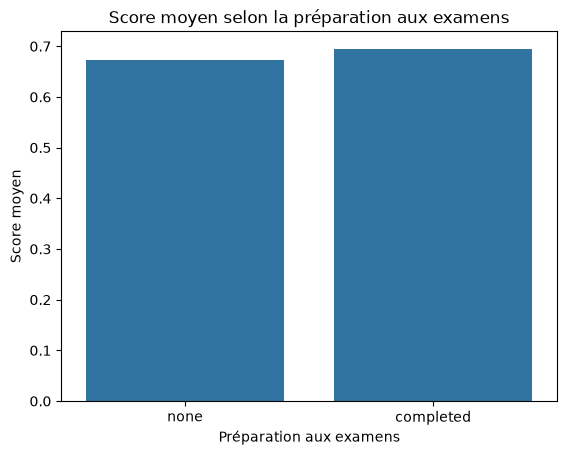

In [690]:
sns.barplot(
    data=df_clean,
    x='test preparation course',
    y='score moyen',
    errorbar=None
)

plt.title('Score moyen selon la préparation aux examens')
plt.xlabel('Préparation aux examens')
plt.ylabel('Score moyen')
plt.show()

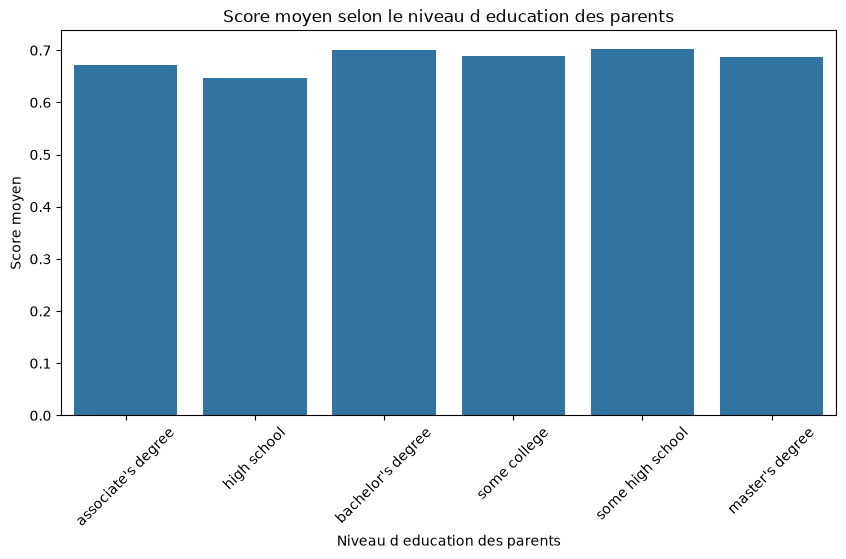

In [691]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='parental level of education',
    y='score moyen',
    errorbar=None
)

plt.title('Score moyen selon le niveau d education des parents')
plt.xlabel('Niveau d education des parents')
plt.ylabel('Score moyen')
plt.xticks(rotation=45)
plt.show()

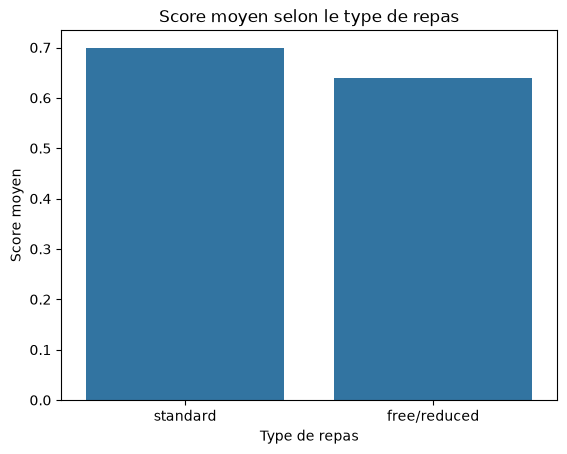

In [692]:
sns.barplot(
    data=df_clean,
    x='lunch',
    y='score moyen',
    errorbar=None
)

plt.title('Score moyen selon le type de repas')
plt.xlabel('Type de repas')
plt.ylabel('Score moyen')
plt.show()

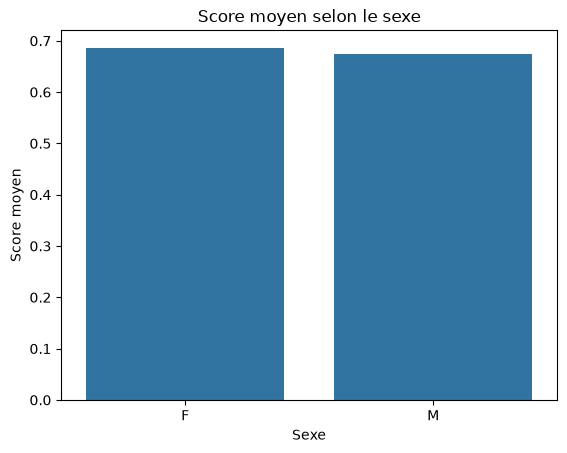

In [693]:
sns.barplot(
    data=df_clean,
    x='sex',
    y='score moyen',
    errorbar=None
)

plt.title('Score moyen selon le sexe')
plt.xlabel('Sexe')
plt.ylabel('Score moyen')
plt.show()

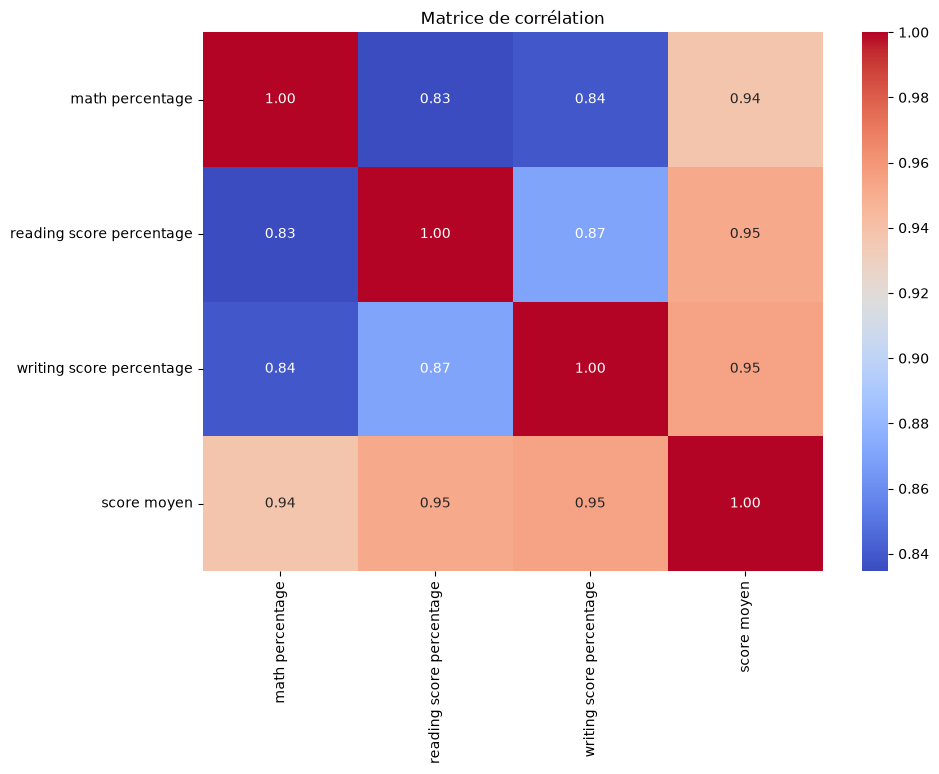

In [698]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matrice de corrélation')
plt.show()